In [1]:
import pandas as pd

df = pd.read_csv('data/dataDressel.csv')
print(df.shape)
print(df.columns.tolist())
df.head()

(470, 13)
['number', 'excavation', 'type', 'chronology', 'exterior_diam', 'inside_diam', 'rim_h', 'rim_w', 'shape_w', 'rim_inside_h', 'rim_w_2', 'protruding_rim', 'site']


,number,excavation,type,chronology,exterior_diam,inside_diam,rim_h,rim_w,shape_w,rim_inside_h,rim_w_2,protruding_rim,site
0,1,delicias,Dressel B,A,150,120,44,24,11,40,9,40,delicias
1,2,delicias,Dressel B,A,140,102,46,30,7,45,16,39,delicias
2,3,delicias,Dressel B,A,150,110,45,25,11,41,22,36,delicias
3,4,delicias,Dressel E,C,180,90,35,40,14,28,35,9,delicias
4,5,delicias,Dressel B,A,130,86,44,27,12,36,17,32,delicias


## Assess: Data Understanding

- The dataset contains **470 amphorae** from **5 workshops** and 13 columns.
- **Class balance:** workshops are moderately imbalanced (Delicias 128 jars, Villaseca 58),
  so models will be evaluated with per-workshop recall, not only overall accuracy.
- **`excavation`** is identical to the target `site` and will be dropped to prevent data leakage.
- **`number`** is an ID column with no predictive meaning and will be dropped.
- The **8 shape measurements** are complete integers with no missing values.
- **`chronology`** has 8 missing values. `type` and `chronology` are closely related,
  because amphora types are used for dating.
- Since the questions focus on shape, the model will use the 8 measurements as features.
  `type` and `chronology` will be used for descriptive analysis.

## Analyze: Exploratory Data Analysis

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

MEASUREMENT_COLS = ['exterior_diam', 'inside_diam', 'rim_h', 'rim_w',
                    'shape_w', 'rim_inside_h', 'rim_w_2', 'protruding_rim']
TARGET = 'site'
SITE_ORDER = df[TARGET].value_counts().index.tolist()

sns.set_theme(style='whitegrid')


def save_figure(fig, filename):
    """Save a matplotlib figure to the images folder.

    Args:
        fig (matplotlib.figure.Figure): The figure to save.
        filename (str): File name, e.g. 'class_balance.png'.
    """
    fig.savefig(f'images/{filename}', dpi=150, bbox_inches='tight')

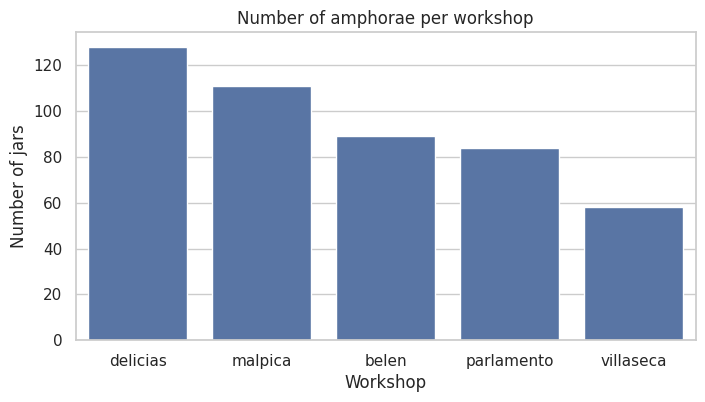

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=df, x=TARGET, order=SITE_ORDER, ax=ax)
ax.set_title('Number of amphorae per workshop')
ax.set_xlabel('Workshop')
ax.set_ylabel('Number of jars')
save_figure(fig, 'class_balance.png')
plt.show()

       exterior_diam  inside_diam  rim_h  rim_w  shape_w  rim_inside_h  \
count          470.0        470.0  470.0  470.0    470.0         470.0   
mean           166.9         94.5   35.4   36.3      9.5          28.4   
std             12.8         10.1    3.6    4.8      1.4           3.6   
min            120.0         70.0   25.0   15.0      5.0          18.0   
25%            160.0         90.0   34.0   34.0      9.0          26.0   
50%            170.0         90.0   35.0   37.0     10.0          28.0   
75%            175.0        100.0   37.0   40.0     10.0          30.0   
max            210.0        140.0   56.0   48.0     14.0          45.0   

       rim_w_2  protruding_rim  
count    470.0           470.0  
mean      30.3            18.9  
std        5.4             6.6  
min        7.0             5.0  
25%       28.0            14.0  
50%       31.0            18.0  
75%       34.0            23.0  
max       44.0            42.0  


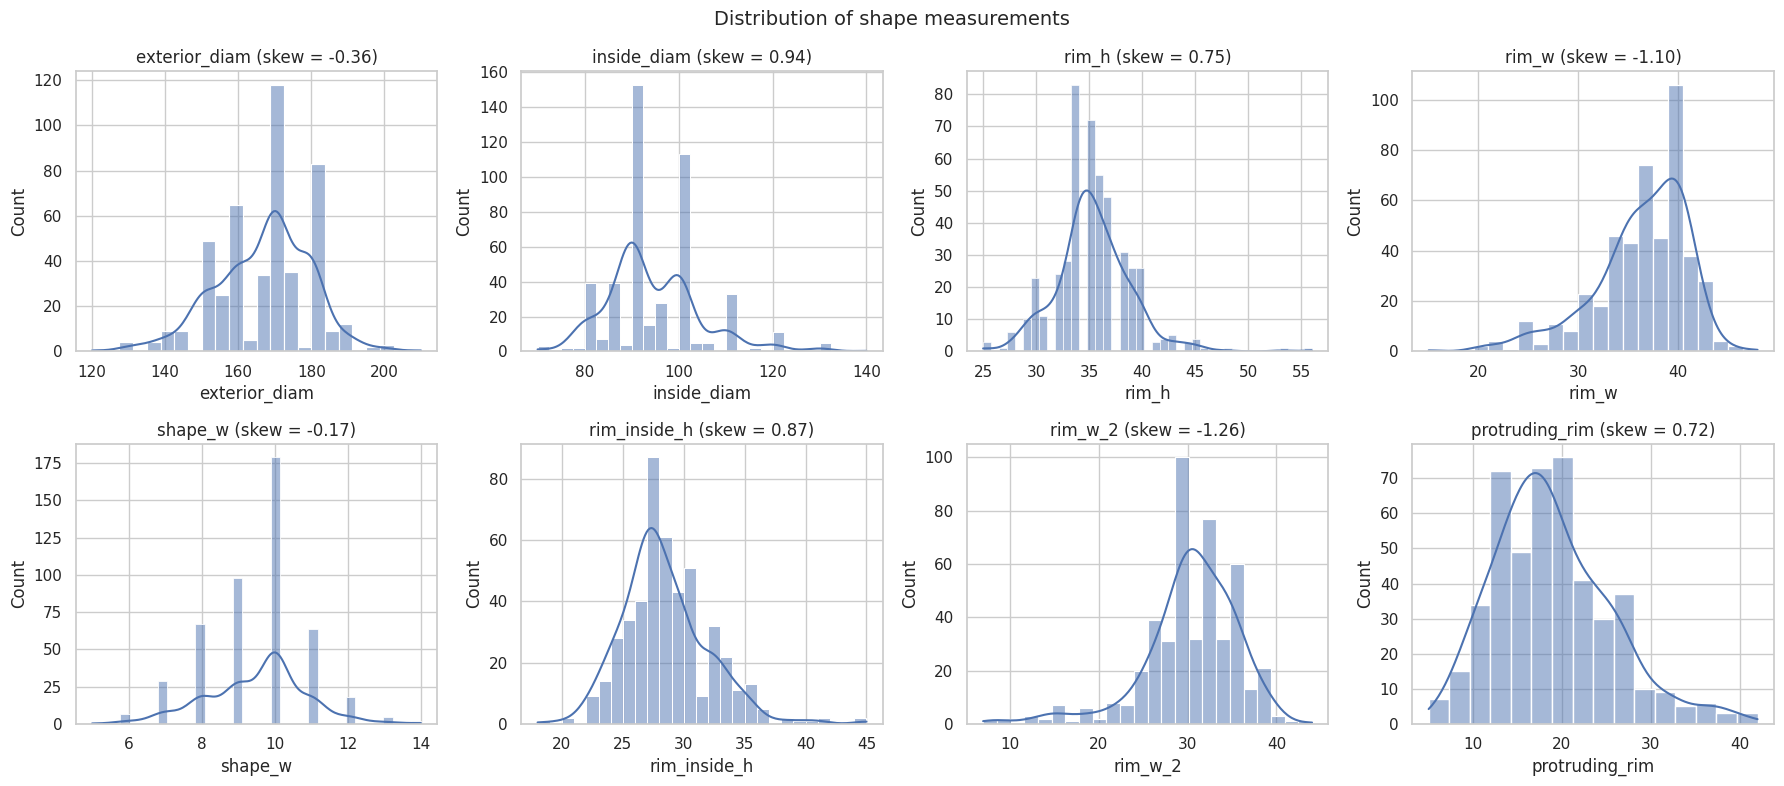

In [4]:
print(df[MEASUREMENT_COLS].describe().round(1))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, MEASUREMENT_COLS):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f'{col} (skew = {df[col].skew():.2f})')
fig.suptitle('Distribution of shape measurements', fontsize=14)
fig.tight_layout()
save_figure(fig, 'distributions.png')
plt.show()

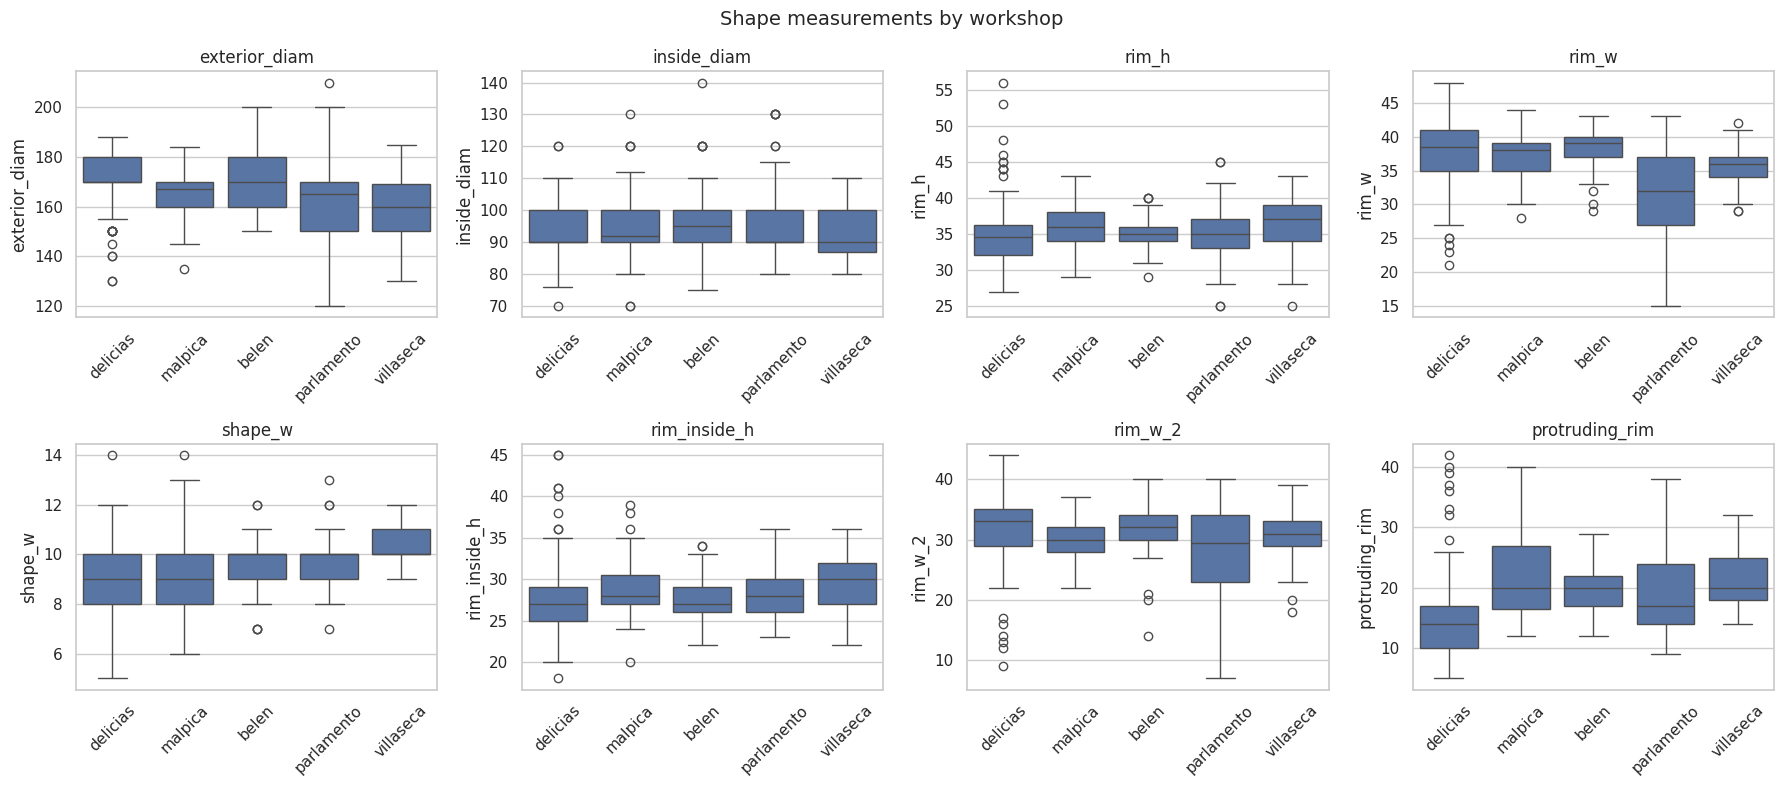

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, MEASUREMENT_COLS):
    sns.boxplot(data=df, x=TARGET, y=col, order=SITE_ORDER, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
fig.suptitle('Shape measurements by workshop', fontsize=14)
fig.tight_layout()
save_figure(fig, 'measurements_by_workshop.png')
plt.show()

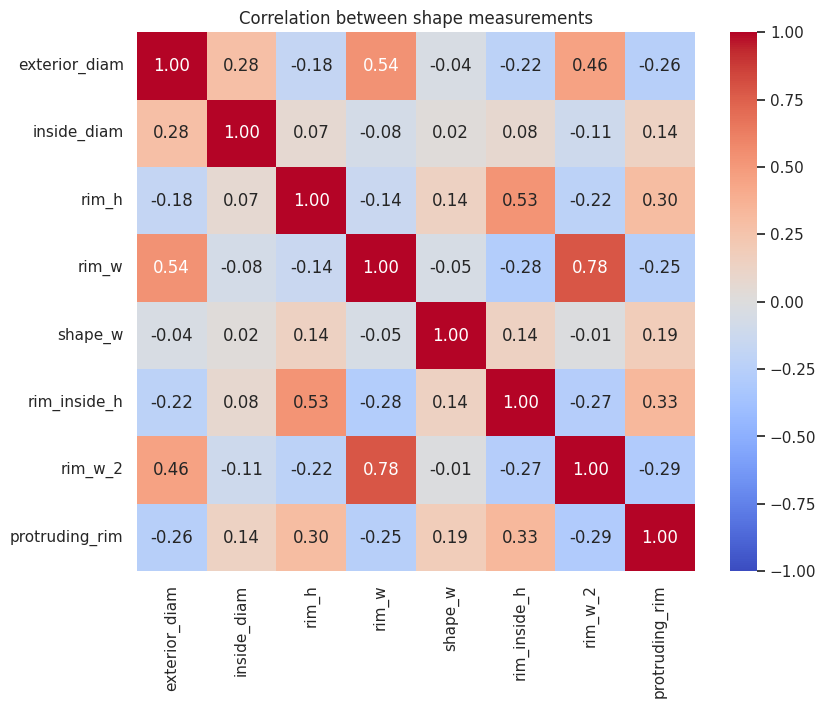

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[MEASUREMENT_COLS].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation between shape measurements')
save_figure(fig, 'correlations.png')
plt.show()

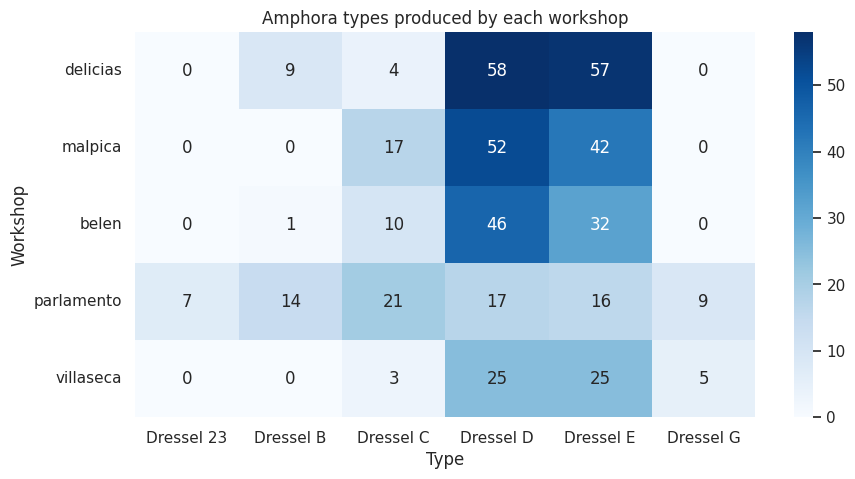

In [7]:
type_by_site = pd.crosstab(df[TARGET], df['type']).loc[SITE_ORDER]

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(type_by_site, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_title('Amphora types produced by each workshop')
ax.set_xlabel('Type')
ax.set_ylabel('Workshop')
save_figure(fig, 'types_by_workshop.png')
plt.show()

- **Workshop medians:** Delicias jars have a much less protruding rim (14 mm vs 17–20 mm
  elsewhere), and Parlamento jars have a narrower rim (32 mm vs 38–39 mm). Inside diameter,
  rim height, shape width and inner rim height differ by only a few millimetres between
  workshops, so they are likely weaker clues on their own.
- **Expectation:** because differences are small and spread across several measurements,
  a model will need to combine features to separate workshops.

## Clean: Data Preparation

In [8]:
def find_outliers(data, columns, threshold=4):
    """Return rows where any column is more than `threshold` standard deviations from its mean.

    Args:
        data (pd.DataFrame): The dataset.
        columns (list): Numeric columns to check.
        threshold (float): Number of standard deviations that counts as extreme.

    Returns:
        pd.DataFrame: Rows containing at least one extreme value.
    """
    z_scores = (data[columns] - data[columns].mean()) / data[columns].std()
    return data[(z_scores.abs() > threshold).any(axis=1)]


outliers = find_outliers(df, MEASUREMENT_COLS)
print("Number of outlier jars:", len(outliers))
outliers[['site', 'type'] + MEASUREMENT_COLS]

Number of outlier jars: 7


,site,type,exterior_diam,inside_diam,rim_h,rim_w,shape_w,rim_inside_h,rim_w_2,protruding_rim
1,delicias,Dressel B,140,102,46,30,7,45,16,39
100,delicias,Dressel B,150,100,53,21,8,41,14,42
101,delicias,Dressel B,140,105,56,25,10,45,12,20
327,belen,Dressel E,170,140,34,37,9,25,32,17
339,parlamento,Dressel 23,150,90,33,15,10,28,30,35
393,parlamento,Dressel B,140,130,34,21,10,30,7,25
395,parlamento,Dressel B,150,110,45,24,9,32,8,34


In [9]:
def clean_data(data):
    """Prepare the amphorae dataset for analysis and modeling.

    Steps:
        1. Drop 'number' (an ID with no predictive meaning).
        2. Drop 'excavation' (an exact copy of the target 'site', which would leak the answer).
        3. Fill missing 'chronology' values with 'Unknown'.

    Args:
        data (pd.DataFrame): The raw dataset.

    Returns:
        pd.DataFrame: The cleaned dataset.
    """
    cleaned = data.drop(columns=['number', 'excavation'])
    cleaned['chronology'] = cleaned['chronology'].fillna('Unknown')
    return cleaned


df_clean = clean_data(df)
print(df_clean.shape)
print("Missing values remaining:", df_clean.isnull().sum().sum())

(470, 11)
Missing values remaining: 0


### Cleaning decisions

- **Dropped `number`:** an ID column with no relationship to the workshop.
- **Dropped `excavation`:** identical to the target `site`; keeping it would let the model
  read the answer (data leakage).
- **Missing `chronology` (8 rows):** filled with `"Unknown"` instead of dropping the rows.
  `chronology` is used only for descriptive analysis, not as a model feature, so filling it
  cannot bias the model, and keeping the rows preserves all 470 jars' measurements.
- **Categorical variables:** the target `site` is used directly as text labels, which
  scikit-learn classifiers accept without encoding. `type` and `chronology` are not model
  features, because the questions focus on shape and both are closely tied to dating.
- **Outliers:** [to be completed after reviewing the outlier rows]

## Model: Predicting the Workshop from Jar Shape

Three models are compared:
1. **Baseline:** always predicts the most common workshop (Delicias). Any useful model must beat this.
2. **Logistic Regression:** a simple, interpretable model. Features are standardized first,
   because the measurements are on different scales.
3. **Random Forest:** combines many decision trees and can capture non-linear patterns.
   `class_weight='balanced'` gives smaller workshops equal importance.

The data is split into 75% training and 25% testing. The split is stratified, so each
workshop appears in the same proportion in both sets.

In [10]:
from sklearn.model_selection import train_test_split

X = df_clean[MEASUREMENT_COLS]
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (352, 8)
Test set: (118, 8)


In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, f1_score

models = {
    'Baseline (most frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=42
    ),
}


def evaluate_model(model, X_train, X_test, y_train, y_test):
    """Train a model and return its scores on the test set.

    Args:
        model: A scikit-learn classifier.
        X_train, X_test (pd.DataFrame): Training and test features.
        y_train, y_test (pd.Series): Training and test labels.

    Returns:
        dict: Accuracy, macro-averaged recall and macro-averaged F1 score.
    """
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    return {
        'Accuracy': accuracy_score(y_test, predictions),
        'Recall (macro)': recall_score(y_test, predictions, average='macro'),
        'F1 (macro)': f1_score(y_test, predictions, average='macro'),
    }

In [12]:
results = {
    name: evaluate_model(model, X_train, X_test, y_train, y_test)
    for name, model in models.items()
}

results_df = pd.DataFrame(results).T.round(3)
results_df

,Accuracy,Recall (macro),F1 (macro)
Baseline (most frequent),0.271,0.200,0.085
Logistic Regression,0.449,0.424,0.431
Random Forest,0.458,0.441,0.446


In [13]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='recall_macro')
    cv_results[name] = {'CV recall (mean)': scores.mean(), 'CV recall (std)': scores.std()}

pd.DataFrame(cv_results).T.round(3)

,CV recall (mean),CV recall (std)
Baseline (most frequent),0.200,0.000
Logistic Regression,0.492,0.012
Random Forest,0.571,0.026


### Model comparison

- The **baseline** reaches 27% accuracy and 20% macro recall by always predicting Delicias.
- **Logistic Regression** (45% accuracy, 42% macro recall) and **Random Forest**
  (46% accuracy, 44% macro recall) both clearly beat the baseline, so shape measurements
  carry real information about which workshop made a jar.
- The difference between the two models is about one jar in a 118-jar test set,
  so they perform roughly equally. Random Forest is used for the remaining analysis
  because it provides feature importances.
- Accuracy stays below 50%, which matches the exploration: workshops differ by only a
  few millimetres. This suggests the workshops produced very similar jars, consistent
  with the idea that they shared or copied production techniques.

## Evaluate: How Well Does the Model Work, and What Does It Rely On?

In [14]:
from sklearn.metrics import classification_report

rf_model = models['Random Forest']
rf_predictions = rf_model.predict(X_test)

print(classification_report(y_test, rf_predictions, labels=SITE_ORDER))

              precision    recall  f1-score   support

    delicias       0.53      0.56      0.55        32
     malpica       0.41      0.43      0.42        28
       belen       0.41      0.50      0.45        22
  parlamento       0.42      0.38      0.40        21
   villaseca       0.56      0.33      0.42        15

    accuracy                           0.46       118
   macro avg       0.47      0.44      0.45       118
weighted avg       0.46      0.46      0.46       118



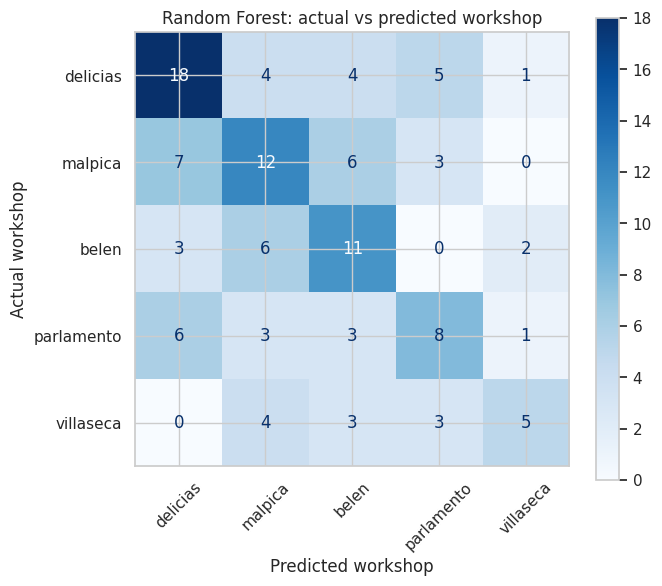

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_predictions, labels=SITE_ORDER, cmap='Blues', ax=ax
)
ax.set_title('Random Forest: actual vs predicted workshop')
ax.set_xlabel('Predicted workshop')
ax.set_ylabel('Actual workshop')
ax.tick_params(axis='x', rotation=45)
save_figure(fig, 'confusion_matrix.png')
plt.show()

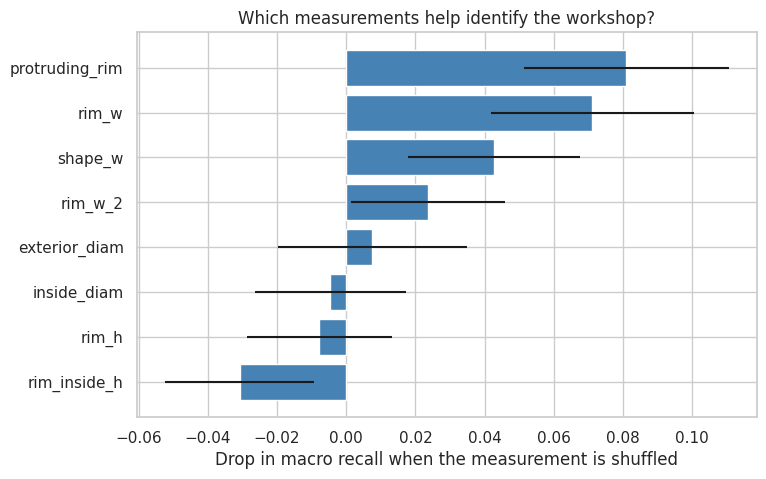

,measurement,importance,std
7,protruding_rim,0.081,0.030
3,rim_w,0.071,0.029
4,shape_w,0.043,0.025
6,rim_w_2,0.024,0.022
0,exterior_diam,0.008,0.027
1,inside_diam,-0.005,0.022
2,rim_h,-0.008,0.021
5,rim_inside_h,-0.031,0.022


In [16]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model, X_test, y_test, n_repeats=30,
    scoring='recall_macro', random_state=42
)

importance_df = pd.DataFrame({
    'measurement': MEASUREMENT_COLS,
    'importance': perm.importances_mean,
    'std': perm.importances_std,
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance_df['measurement'], importance_df['importance'],
        xerr=importance_df['std'], color='steelblue')
ax.invert_yaxis()
ax.set_title('Which measurements help identify the workshop?')
ax.set_xlabel('Drop in macro recall when the measurement is shuffled')
save_figure(fig, 'feature_importance.png')
plt.show()

importance_df.round(3)

### Evaluation summary

**Model reliability:** 5-fold cross-validation gives a more reliable estimate than a single
118-jar test set. Random Forest reaches **57% macro recall (±3%)**, compared with 49% for
Logistic Regression and 20% for the baseline, so Random Forest is the best model.

**Per workshop:** Delicias is the easiest workshop to identify (56% recall) and Villaseca
the hardest (33% recall). However, Villaseca has the highest precision (56%): when the model
predicts Villaseca, it is usually correct.

**Most common confusions:** Malpica ↔ Belén (12 jars), Delicias ↔ Parlamento (11) and
Delicias ↔ Malpica (11). Belén and Parlamento are almost never confused. Delicias and
Parlamento both produced older Dressel B jars, which may explain their overlap.

**Question 1: most important measurements:**
1. `protruding_rim` (how far the rim sticks out)
2. `rim_w` (rim width)
3. `shape_w`
4. `rim_w_2`

Overall jar size (`exterior_diam`, `inside_diam`) and rim height contribute almost nothing.
**The rim, not the size, carries the workshop's fingerprint.**

In [17]:
distances = pd.read_csv('data/riverDistances.csv')
print(distances.shape)
distances

(20, 3)


,from,to,spatial
0,parlamento,belen,98
1,parlamento,delicias,126
2,parlamento,malpica,108
3,parlamento,villaseca,133
4,belen,parlamento,98
5,belen,delicias,29
6,belen,malpica,11
7,belen,villaseca,33
8,delicias,parlamento,126
9,delicias,belen,29


In [18]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

# Predict every jar using models that never saw it during training
cv_predictions = cross_val_predict(rf_model, X, y, cv=cv)
cm = pd.DataFrame(
    confusion_matrix(y, cv_predictions, labels=SITE_ORDER),
    index=SITE_ORDER, columns=SITE_ORDER
)
site_counts = y.value_counts()


def pair_confusion_rate(matrix, counts, site_a, site_b):
    """Share of two workshops' jars that the model assigned to the other workshop.

    Args:
        matrix (pd.DataFrame): Confusion matrix (rows = actual, columns = predicted).
        counts (pd.Series): Number of jars per workshop.
        site_a, site_b (str): The two workshops to compare.

    Returns:
        float: Confusion rate between 0 and 1.
    """
    mixups = matrix.loc[site_a, site_b] + matrix.loc[site_b, site_a]
    return mixups / (counts[site_a] + counts[site_b])


# Keep each pair once (A-B, not also B-A)
pairs = distances[distances['from'] < distances['to']].copy()
pairs = pairs.rename(columns={'spatial': 'river_distance'})
pairs['confusion_rate'] = [
    pair_confusion_rate(cm, site_counts, a, b)
    for a, b in zip(pairs['from'], pairs['to'])
]
pairs = pairs.sort_values('river_distance').reset_index(drop=True)

correlation = pairs['river_distance'].corr(pairs['confusion_rate'], method='spearman')
print(f"Spearman correlation between distance and confusion: {correlation:.2f}")
pairs.round(3)

Spearman correlation between distance and confusion: -0.39


,from,to,river_distance,confusion_rate
0,belen,malpica,11,0.230
1,delicias,malpica,17,0.155
2,belen,delicias,29,0.088
3,belen,villaseca,33,0.088
4,malpica,villaseca,50,0.071
5,delicias,villaseca,67,0.032
6,belen,parlamento,98,0.069
7,malpica,parlamento,108,0.097
8,delicias,parlamento,126,0.118
9,parlamento,villaseca,133,0.085


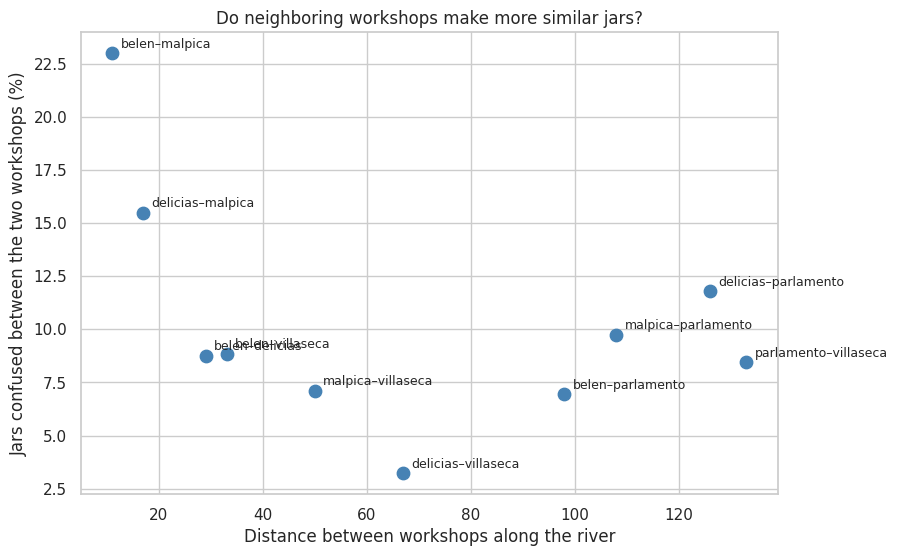

In [19]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(pairs['river_distance'], pairs['confusion_rate'] * 100, s=80, color='steelblue')

for _, row in pairs.iterrows():
    ax.annotate(f"{row['from']}–{row['to']}",
                (row['river_distance'], row['confusion_rate'] * 100),
                textcoords='offset points', xytext=(6, 4), fontsize=9)

ax.set_title('Do neighboring workshops make more similar jars?')
ax.set_xlabel('Distance between workshops along the river')
ax.set_ylabel('Jars confused between the two workshops (%)')
save_figure(fig, 'distance_vs_similarity.png')
plt.show()

### Question 2: Did neighboring workshops make more similar jars?

To measure similarity, every jar was predicted using cross-validation, and the share of
jars confused between each pair of workshops was calculated (adjusted for workshop size).

- **Distance and confusion are moderately related** (Spearman correlation: −0.39).
- **The effect is local:** the two closest pairs are by far the most similar.
  Belén–Malpica (11 km) confuse about 23% of their jars, and Delicias–Malpica (17 km)
  about 15%. All other pairs fall between 3% and 12%, regardless of distance.
- **Exception:** Delicias and Parlamento are 126 km apart but still confuse about 12% of
  their jars, the highest among distant pairs. Both produced older Dressel B jars, so
  shared time period may also drive similarity.
- **Caveat:** with only 10 workshop pairs, this pattern is suggestive rather than conclusive.

**Answer:** workshops very close to each other produced noticeably more similar jars,
which is consistent with neighbors sharing or copying techniques. Beyond about 20 km,
distance has little effect.

## Scenario: An Archaeologist Finds New Jars

The final model is retrained on all 470 jars, so it learns from as much data as possible.
It is then used to predict the workshop of two hypothetical new jars:
- **Jar A** has a short, barely protruding rim (13 mm), the feature most typical of Delicias.
- **Jar B** has a narrow rim (31 mm), the feature most typical of Parlamento.

All other measurements are set to typical values.

In [20]:
final_model = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=42
)
final_model.fit(X, y)


def predict_workshop_probabilities(model, jars):
    """Return the model's probability for each workshop, for each jar.

    Args:
        model: A fitted scikit-learn classifier with predict_proba.
        jars (pd.DataFrame): Jar measurements, one row per jar.

    Returns:
        pd.DataFrame: Probabilities (in %), one column per workshop.
    """
    probabilities = model.predict_proba(jars[MEASUREMENT_COLS])
    result = pd.DataFrame(probabilities, index=jars.index, columns=model.classes_)
    return (result[SITE_ORDER] * 100).round(1)


typical_jar = df_clean[MEASUREMENT_COLS].median()

jar_a = typical_jar.copy()
jar_a['protruding_rim'] = 13

jar_b = typical_jar.copy()
jar_b['rim_w'] = 31

new_jars = pd.DataFrame([jar_a, jar_b], index=['Jar A (short rim)', 'Jar B (narrow rim)'])
print(new_jars)
predict_workshop_probabilities(final_model, new_jars)

                    exterior_diam  inside_diam  rim_h  rim_w  shape_w  \
Jar A (short rim)           170.0         90.0   35.0   37.0     10.0   
Jar B (narrow rim)          170.0         90.0   35.0   31.0     10.0   

                    rim_inside_h  rim_w_2  protruding_rim  
Jar A (short rim)           28.0     31.0            13.0  
Jar B (narrow rim)          28.0     31.0            18.0  


,delicias,malpica,belen,parlamento,villaseca
Jar A (short rim),34.0,23.0,6.7,34.0,2.3
Jar B (narrow rim),3.3,14.0,15.3,63.3,4.0


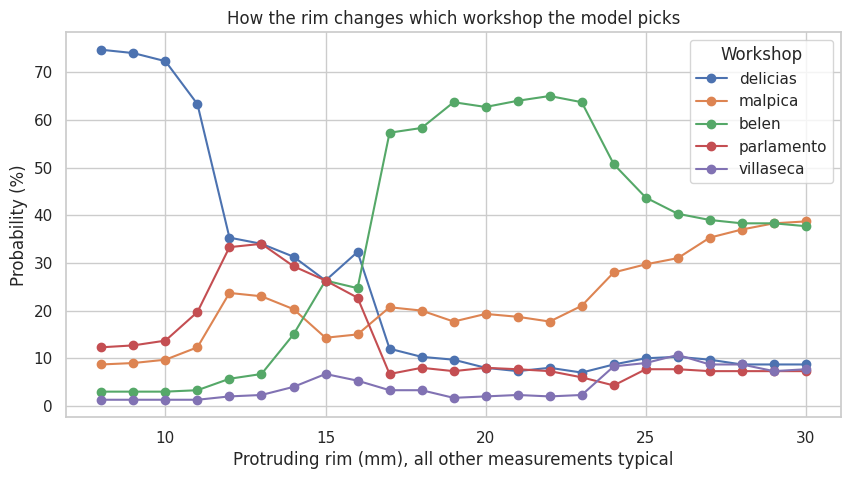

In [21]:
rim_values = range(8, 31)
what_if = pd.DataFrame([typical_jar] * len(rim_values))
what_if['protruding_rim'] = list(rim_values)
what_if.index = list(rim_values)

what_if_probs = predict_workshop_probabilities(final_model, what_if)

fig, ax = plt.subplots(figsize=(10, 5))
for site in SITE_ORDER:
    ax.plot(what_if_probs.index, what_if_probs[site], marker='o', label=site)
ax.set_title('How the rim changes which workshop the model picks')
ax.set_xlabel('Protruding rim (mm), all other measurements typical')
ax.set_ylabel('Probability (%)')
ax.legend(title='Workshop')
save_figure(fig, 'what_if_rim.png')
plt.show()

print(predict_workshop_probabilities(final_model, new_jars).to_string())

### Question 4: Which workshop made a newly found jar?

The final Random Forest was retrained on all 470 jars and used on two hypothetical jars.

- **Jar A** (short rim, protruding 13 mm): Delicias 34%, [Parlamento X%], Malpica 23%.
  The model leans toward Delicias but is uncertain, because a 13 mm rim falls in a range
  where several workshops overlap.
- **Jar B** (narrow rim, 31 mm wide): [Parlamento X%] … The narrow rim points clearly
  to Parlamento.

**What-if analysis:** holding all other measurements at typical values and changing only
how far the rim protrudes:
- **8–11 mm:** Delicias, with about 70–75% confidence
- **13–16 mm:** uncertain, with Delicias, Parlamento and Malpica each at about 25–35%
- **17–24 mm:** Belén, with about 57–65% confidence
- **25–30 mm:** Belén and Malpica roughly tied

Villaseca is never the most likely workshop, which explains why it is the hardest to identify.

**Interpretation:** for an archaeologist, the model works best as a *shortlist* tool rather
than a final verdict. A very short rim strongly suggests Delicias, while a mid-length rim
suggests Belén. This analysis changes one measurement at a time; real jars vary in all
measurements together.

In [22]:
print(predict_workshop_probabilities(final_model, new_jars).to_string())

                    delicias  malpica  belen  parlamento  villaseca
Jar A (short rim)       34.0     23.0    6.7        34.0        2.3
Jar B (narrow rim)       3.3     14.0   15.3        63.3        4.0


### Question 4: Which workshop made a newly found jar?

The final Random Forest was retrained on all 470 jars and used on two hypothetical jars,
with all measurements set to typical values except one.

| Jar | Delicias | Malpica | Belén | Parlamento | Villaseca |
|---|---|---|---|---|---|
| **A**: short rim (protrudes 13 mm) | **34%** | 23% | 7% | **34%** | 2% |
| **B**: narrow rim (31 mm wide) | 3% | 14% | 15% | **63%** | 4% |

- **Jar A** is an exact tie between Delicias and Parlamento. A 13 mm rim is short, but
  falls in a range where several workshops overlap. This matches the earlier finding that
  Delicias and Parlamento jars are often confused.
- **Jar B** points clearly to Parlamento (63%). A narrow rim is Parlamento's strongest signature.

**What-if analysis:** changing only how far the rim protrudes:
- **8–11 mm:** Delicias, with about 70–75% confidence
- **13–16 mm:** uncertain, with Delicias, Parlamento and Malpica each at about 25–35%
- **17–24 mm:** Belén, with about 57–65% confidence
- **25–30 mm:** Belén and Malpica roughly tied

Villaseca is never the most likely workshop, which explains why it is the hardest to identify.

**Interpretation:** for an archaeologist, the model works best as a *shortlist* tool rather
than a final verdict. It can narrow five workshops down to one or two candidates. This
analysis changes one measurement at a time, while real jars vary in all measurements together.

## Conclusions

1. **Which measurements matter most?** The rim carries the workshop's fingerprint: how far
   it protrudes and how wide it is. Overall jar size and rim height contribute almost nothing.
2. **Did neighboring workshops make more similar jars?** Partly. The two closest pairs
   (11 and 17 km apart) are by far the most similar, but beyond about 20 km distance has
   little effect. Shared time period, such as both Delicias and Parlamento producing older
   Dressel B jars, also creates similarity.
3. **How accurate is the model?** Random Forest identifies the correct workshop with 57%
   macro recall in cross-validation, almost 3× better than guessing (20%). The workshops
   produced very similar jars, so perfect identification is not possible from shape alone.
4. **Which workshop made a new jar?** The model gives useful probabilities: a narrow rim
   points strongly to Parlamento (63%), while a short rim narrows the choice to Delicias
   or Parlamento.

**Limitations:** the dataset is small (470 jars, 5 workshops), the diameters appear to be
rounded to the nearest 5–10 mm, and the type and chronology of the jars may confound the
shape differences between workshops.